In [1]:
import sys

import sys
from cells_simulation import *

import sys
sys.path.insert(0, "../../")

from RealTrace_paper_analysis.plotting_src.read_ggp_run import * # you might need to change these two line, such that you can use read ggp_run

import numpy as np
import subprocess

In [2]:

# ========== Simulation parameters ========== #
save_dataset = True    # saves data set as csv
run_ggp = True         # runs the ggp code (located in "../bin/" relative to this nb)

dt = 0.01
dt_measument = 3 # in minutes

n_cells = 1000 # number of cells that will be simulated
discard_cells = 20
lanes = 1

log_length0 = np.log(2)
gfp0 = 24975.8


div_mode = "adder"
division_log_length = None   # for sizer: division, when log_length hits division_log_length
division_time = None          # for timer: division, when cell cycle time hits division_time
division_addition = log_length0       # for adder: divsion, when division_addition in log_length was added in cell cycle


data_set_name = "time_dependent_OU"
# taken from glucose_hi1_f01234578910_b_prediction in data_dany_old_data_output_20221215
parameter_set  =  {"mean_lambda": 0.0114137, 
                    "gamma_lambda": 0.166994,
                    "var_lambda": 4.9481e-06/4.,
                   #
                    "mean_q": 118.524,
                    "gamma_q": 0.0595599,
                    "var_q": 430.055 /4.,
                   # 
                    "beta": 0,
                    "var_x": 0.000136701,
                    "var_g": 12.255,
                    "var_dx": 0.00468653,
                    "var_dg": 1.53195}


In [3]:
def time_dependent_mean(mean, t, a, T):
    return mean*(1+a*np.sin(2*np.pi/T*t))

def simulate_cells_time_dependent_OU(dt, n_cells, parameter_set, div_mode, 
                    division_log_length=None, 
                    division_time=None, 
                    division_addition=None, 
                    log_length0=None,
                    gfp0=None, 
                    tree=True,
                    tmax=np.inf, 
                    verbose=False, 
                    discard_cells=0, 
                    cell_division_model="binomial"):
    if gfp0 == None:
        gfp0 = 3*parameter_set['mean_q']/parameter_set['mean_lambda']
    if log_length0 == None:
        log_length0 = division_log_length-np.log(2)

    cell_queue = [Cell(log_length0, gfp0, parameter_set['mean_lambda'], parameter_set['mean_q'])]

    cells_simulated = []
    no_cells = 0   # total number of cells (in queue and calculated)
    t_total = 0    # the largest t in the current set of cells

    while len(cells_simulated) < n_cells and t_total < tmax:
        if len(cells_simulated)>0:
            idx = get_current_leafs_idx(cell_queue, cells_simulated)
            cell_index = np.random.choice(idx)
        else:
            cell_index = 0

        # print_simulated(cells_simulated)
        # print_queue(cell_queue,cell_index)

        # simulate a random cell in queue
        cell = copy.deepcopy(cell_queue[cell_index])

        # --------------------------------------------------------------- #
        # Simulation on single cell level
        # --------------------------------------------------------------- #
        while True:
            cell.time.append(cell.time[-1]+dt)

            t_total = np.max([t_total, cell.time[-1]])
            if t_total > tmax:
                break
            a = 0.3
            T = 240
            q_ou = single_ou_step(dt, 
                                  time_dependent_mean(parameter_set['mean_q'], cell.time[-1], a, T),                                        
                                  parameter_set['gamma_q'], 
                                parameter_set['var_q'], 
                                cell.qt[-1]) 

            cell = gfp_production(cell, dt, q_ou, parameter_set['beta'])

            lambda_ou = single_ou_step(dt, 
                                       time_dependent_mean(parameter_set['mean_lambda'], cell.time[-1], a, T),
                                        parameter_set['gamma_lambda'], 
                                        parameter_set['var_lambda'], 
                                        cell.lt[-1]) 
            cell = growth(cell, dt, lambda_ou)

            if is_cell_division(cell, div_mode, division_log_length, division_time, division_addition):
                # save the simulated cell
                if discard_cells==0:
                    cells_simulated.append(cell)
                else:
                    discard_cells -= 1
                
                # calc. new init conditions for 2 daugter cells
                cell1, cell2, no_cells = cell_division(cell, parameter_set['var_dx'], 
                                                            parameter_set['var_dg'], 
                                                            no_cells, cell_division_model, dt)

                # remove the simulated cell from queue and add the new ones 
                cell_queue.pop(cell_index)
                cell_queue.append(cell1)
                if tree and discard_cells==0:
                    cell_queue.append(cell2)
                break
            else:
                pass

        if verbose:
            progress_bar_n = np.around(len(cells_simulated)/n_cells*20).astype(int)
            progress_bar = '='*progress_bar_n + ' '*(20-progress_bar_n)
            print("\r|", progress_bar,  "| Progress {:3.0f}%".format(len(cells_simulated)/n_cells*100), " No of cells: ", len(cells_simulated), end='')  
            print('')

    return cells_simulated


# --------- SIMULATE --------- #
cells_simulated = simulate_cells_time_dependent_OU(dt, n_cells, parameter_set, div_mode,
                                division_log_length, 
                                division_time, division_addition, 
                                log_length0=log_length0, gfp0=gfp0, 
                                tree=True,
                                discard_cells=discard_cells)

# Plot

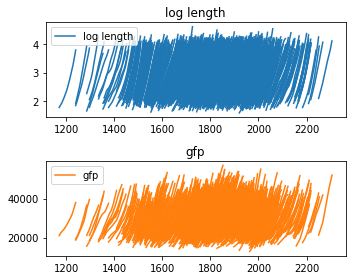

In [4]:

# =============== PLOT =============== #
def plot_cells(cells, n_steps=1):   
    _, axes = plt.subplots(2, figsize=(5,4))
    ax = axes.ravel()

    for j in range(len(cells[::n_steps])):
        cell = copy.deepcopy(cells[j])
        cell.time = np.array(cell.time)

        if n_steps>1:
            ax[0].set_title("log length (showing every {:d}th cell)".format(n_steps))
            ax[1].set_title("gfp (showing every {:d}th cell)".format(n_steps))

        else:
            ax[0].set_title("log length")
            ax[1].set_title("gfp")

        # ax[0].set_ylim([1.2, 2.2])
        
        if len(cells[::n_steps]) <20:
            ax[0].axvline(cell.time[-1], ls='--', color='tab:blue')
            ax[1].axvline(cell.time[-1], ls='--', color='tab:orange')

        if j ==0:
            ax[0].plot(cell.time, np.exp(np.array(cell.log_length)), label='log length', color='tab:blue')
            ax[1].plot(cell.time, np.array(cell.gfp), color='tab:orange', label='gfp')

        else:
            ax[0].plot(cell.time, np.exp(np.array(cell.log_length)), color='tab:blue')
            ax[1].plot(cell.time, np.array(cell.gfp), color='tab:orange')
        

    for j in range(2):
        ax[j].legend()
    plt.tight_layout()
    plt.show()
plot_cells(cells_simulated, n_steps=1)

# Save

In [5]:
base_dir ='../../data_sim_manuscript_temp/{:s}_simulation{:d}'

   
out_dir = mk_missing_dir(base_dir.format(data_set_name, n_cells))

# ----------- SAVE ----------- #
dt_measument = 3 # in minutes

dataset = build_data_set_scale_gfp_noise(cells_simulated, 
                                                parameter_set['var_x'], 
                                                parameter_set['var_g'], 
                                                dt_measument,
                                                atol=dt/10)


dataset["length_noise"] = np.exp(dataset["log_length_noise"])
directory, filename = get_next_file_name(out_dir)

write_csv_config(os.path.join(directory, "csv_config.txt"))

write_param_file(os.path.join(directory, "parameters_sim.txt"), parameter_set) 
param_file = write_param_file_noise(os.path.join(directory, "parameters_noise.txt"), 
                                                parameter_set, 
                                                rel_step=0.1, 
                                                log_noise=0.1, fixed=["beta"]) 
dataset.to_csv(filename)




dataset_full = build_data_set_scale_gfp_noise(cells_simulated[:50], 
                                                parameter_set['var_x'], 
                                                parameter_set['var_g'], 
                                                dt,
                                                atol=dt/10)
filename_full = filename[:-4] + "_full.csv"
dataset_full["length_noise"] = np.exp(dataset_full["log_length_noise"])
dataset_full.to_csv(filename_full)


None


In [6]:

# ----------- RUN ----------- #
run_cmd = "../../RealTrace/bin/RealTrace" + " -c " + os.path.join(directory, "csv_config.txt") + \
    " -b " + param_file + \
    " -t " + str(1e-40) +  " -i " + filename + " -l 0 " + '-m -p' 
print("run: -> \n", run_cmd)
s = subprocess.run(run_cmd, capture_output=True, shell=True)
s

run: -> 
 ../../RealTrace/bin/RealTrace -c ../../data_sim_manuscript_temp/time_dependent_OU_simulation1000/time_dependent_OU_simulation1000_0/csv_config.txt -b ../../data_sim_manuscript_temp/time_dependent_OU_simulation1000/time_dependent_OU_simulation1000_0/parameters_noise.txt -t 1e-40 -i ../../data_sim_manuscript_temp/time_dependent_OU_simulation1000/time_dependent_OU_simulation1000_0/time_dependent_OU_simulation1000_0.csv -l 0 -m -p


CompletedProcess(args='../../RealTrace/bin/RealTrace -c ../../data_sim_manuscript_temp/time_dependent_OU_simulation1000/time_dependent_OU_simulation1000_0/csv_config.txt -b ../../data_sim_manuscript_temp/time_dependent_OU_simulation1000/time_dependent_OU_simulation1000_0/parameters_noise.txt -t 1e-40 -i ../../data_sim_manuscript_temp/time_dependent_OU_simulation1000/time_dependent_OU_simulation1000_0/time_dependent_OU_simulation1000_0.csv -l 0 -m -p', returncode=0, stdout=b"Running... \nTemporary log file '../../data_sim_manuscript_temp/time_dependent_OU_simulation1000/time_dependent_OU_simulation1000_0/time_dependent_OU_simulation1000_0_out/time_dependent_OU_simulation1000_0.log' created\nDone. Log file: ../../data_sim_manuscript_temp/time_dependent_OU_simulation1000/time_dependent_OU_simulation1000_0/time_dependent_OU_simulation1000_0_out/time_dependent_OU_simulation1000_0_success.log\n", stderr=b'')